## Question 1: One-Way ANOVA – Regional Sales

         mean        std  count
Region                         
East    195.0  21.213203      2
North   210.0  14.142136      2
South   245.0   7.071068      2
West    225.0   7.071068      2
F-Statistic: 4.866667
P-Value: 0.080224
Decision: Fail to reject H0


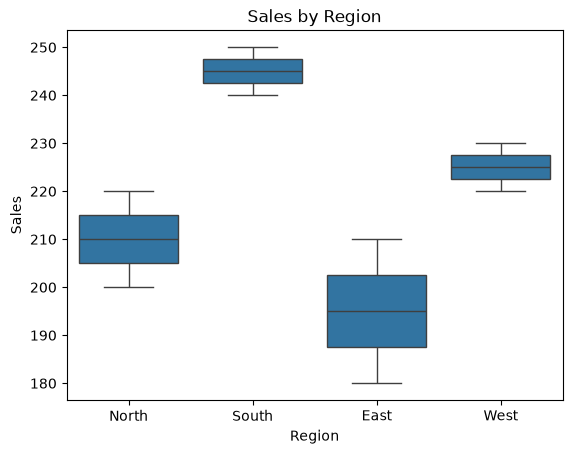

In [1]:
import pandas as pd
from scipy.stats import f_oneway
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame({'Region':['North','North','South','South','East','East','West','West'], 'Sales':[200,220,250,240,180,210,230,220]})
print(df.groupby('Region')['Sales'].agg(['mean','std','count']))
groups = [g['Sales'].to_numpy() for _,g in df.groupby('Region')]
f_stat, p_value = f_oneway(*groups)
print(f'F-Statistic: {f_stat:.6f}')
print(f'P-Value: {p_value:.6f}')
print('Decision:', 'Reject H0' if p_value < 0.05 else 'Fail to reject H0')
sns.boxplot(data=df,x='Region',y='Sales');plt.title('Sales by Region');plt.show()

## Question 2: Two-Way ANOVA – Training and Experience

                          mean  count
Training Experience                  
A        High        80.000000      1
         Low         78.333333      3
B        High        89.000000      3
         Low         85.000000      1
                  sum_sq   df          F    PR(>F)
C(Training)    92.041667  1.0  16.030479  0.010284
C(Experience)  12.041667  1.0   2.097242  0.207229
Residual       28.708333  5.0        NaN       NaN
Note: Two-way interaction cannot be reliably estimated without B/Low observations.


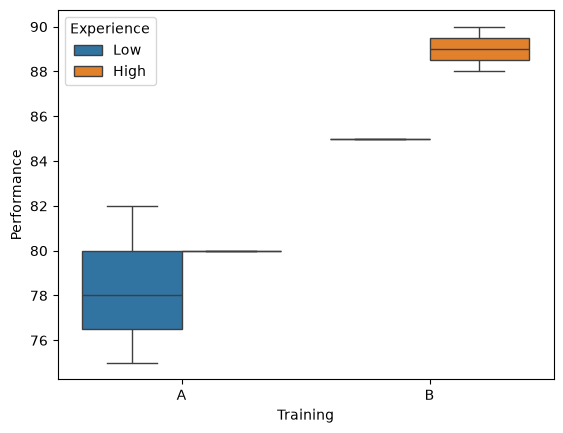

In [2]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame({'Training':['A','A','B','B','A','B','A','B'], 'Experience':['Low','High','Low','High','Low','High','Low','High'], 'Performance':[75,80,85,90,78,88,82,89]})
print(df.groupby(['Training','Experience'])['Performance'].agg(['mean','count']))
# This dataset has no Training B / Low observations; the full interaction is not estimable.
# Fit the additive model and interpret cautiously.
model = ols('Performance ~ C(Training) + C(Experience)',data=df).fit()
print(sm.stats.anova_lm(model,typ=2))
print('Note: Two-way interaction cannot be reliably estimated without B/Low observations.')
sns.boxplot(data=df,x='Training',y='Performance',hue='Experience');plt.show()

## Question 3: VIF – House Price Features

In [6]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Step 1: Create Dataset
df = pd.DataFrame({
    'Area': [1500, 2000, 2500, 3000, 3500],
    'Bedrooms': [3, 4, 3, 5, 4],
    'Bathrooms': [2, 3, 2, 4, 3],
    'House_Price': [300000, 400000, 350000, 500000, 450000]
})

# Step 2: Select Input Features
X = df[['Area', 'Bedrooms', 'Bathrooms']]

# Step 3: Check Perfect Multicollinearity
print("Perfect Dependence Check:")
print((df['Bedrooms'] - df['Bathrooms']).unique())

# Step 4: Remove Redundant Feature
X = X.drop(columns=['Bathrooms'])

# Step 5: Add Constant
X = sm.add_constant(X)

# Step 6: Calculate VIF
vif = pd.DataFrame({
    'Feature': X.columns,
    'VIF': [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

print("\nVIF Results:")
print(vif)

print("\nConclusion:")
print("Bathrooms was removed because it has a perfect")
print("linear relationship with Bedrooms.")
print("The remaining predictors do not have perfect multicollinearity.")

Perfect Dependence Check:
[1]

VIF Results:
    Feature        VIF
0     const  27.421053
1      Area   1.473684
2  Bedrooms   1.473684

Conclusion:
Bathrooms was removed because it has a perfect
linear relationship with Bedrooms.
The remaining predictors do not have perfect multicollinearity.


## Question 4: Independent T-Test – Teaching Methods

Method
Interactive    87.5
Traditional    72.5
Name: Score, dtype: float64
Statistic: -4.242641, P-Value: 0.051317
Decision: Fail to reject H0


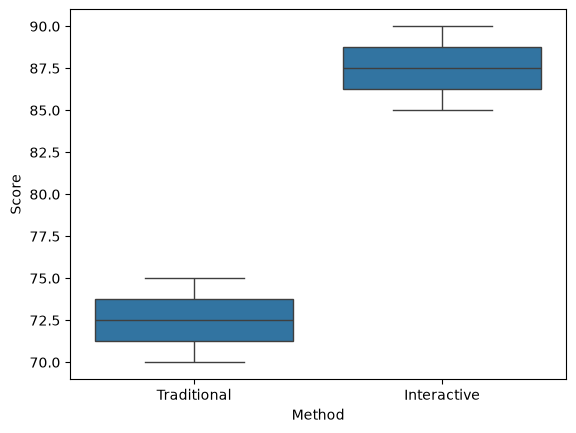

In [4]:
import pandas as pd
from scipy.stats import ttest_ind
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame({'Method':['Traditional','Traditional','Interactive','Interactive'], 'Score':[70,75,85,90]})
a = df.loc[df.Method=='Traditional','Score']
b = df.loc[df.Method=='Interactive','Score']
print(df.groupby('Method')['Score'].mean())
t_stat,p_value = ttest_ind(a,b,equal_var=True)
print(f'Statistic: {t_stat:.6f}, P-Value: {p_value:.6f}')
print('Decision:', 'Reject H0' if p_value<0.05 else 'Fail to reject H0')
sns.boxplot(data=df,x='Method',y='Score');plt.show()

## Question 5: Pearson Correlation – Workout Time

Correlation Coefficient: 0.984798
P-Value: 0.002245


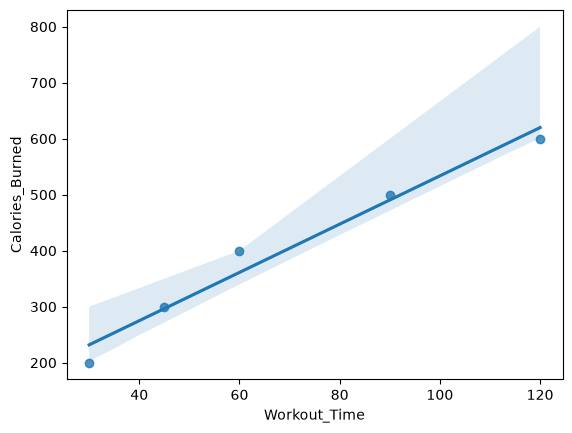

In [5]:
import pandas as pd
from scipy.stats import pearsonr
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame({'Workout_Time':[30,45,60,90,120], 'Calories_Burned':[200,300,400,500,600]})
r,p = pearsonr(df['Workout_Time'],df['Calories_Burned'])
print(f'Correlation Coefficient: {r:.6f}')
print(f'P-Value: {p:.6f}')
sns.regplot(data=df,x='Workout_Time',y='Calories_Burned');plt.show()